In [1]:
pip install causalml -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

from causalml.optimize import PolicyLearner
from causalml.inference.meta import BaseXRegressor
from causalml.inference.meta import BaseDRRegressor
from causalml.dataset import synthetic_data

np.random.seed(42)

ERROR:duecredit:Failed to import duecredit due to No module named 'duecredit'


In [4]:
# Policy Learner Strategy
def tau_policy_learner_strategy(df : pd.DataFrame):
  return df.apply(lambda x : x.tau_real if x.policy_pred == 1 else 0,axis=1).sum()

# Best Strategy
def tau_best_strategy(df : pd.DataFrame):
  return df.apply(lambda x : x.tau_real if x.tau_real > 0 else 0,axis=1).sum()

# Random Assignment Strategy
def tau_random_assignment_strategy(df : pd.DataFrame):
  p = np.random.randint(0,2,len(df))
  df = df.assign(random_treatment = p)
  return df.apply(lambda x : x.tau_real if x.random_treatment > 0 else 0,axis=1).sum()

# Case 1: Positive Treatment Effect


In [5]:
# Generate synthetic data
def get_synthetic_data(n_samples):
  y, X, w, tau, b, e = synthetic_data(mode=1, n=n_samples, p=5, sigma=1.0)
  return  X, y, w, tau, e

In [6]:
X, y, w, tau, e = get_synthetic_data(n_samples=10000)

In [7]:
X_train, X_test, y_train, y_test, w_train, w_test, tau_train, tau_test = train_test_split(X, y, w, tau, test_size=0.2,random_state=42)
policy_learner = PolicyLearner(policy_learner=DecisionTreeClassifier(max_depth=2),calibration=True)

In [8]:
policy_learner.fit(X=X_train,treatment=w_train,y=y_train)

PolicyLearner(model_mu=GradientBoostingRegressor(),
	model_w=GradientBoostingClassifier(),
	model_pi=DecisionTreeClassifier(max_depth=2))

In [9]:
df_test = pd.DataFrame(X_test)
df_test = df_test.assign(tau_real = tau_test)
df_test = df_test.assign(policy_pred = policy_learner.predict(X=X_test).ravel())

In [10]:
print(f'Policy Learner strategy tau: {tau_policy_learner_strategy(df = df_test)}')
print(f'Random Assignment strategy tau: {tau_random_assignment_strategy(df = df_test)}')
print(f'Oracle (Best) strategy tau: {tau_best_strategy(df = df_test)}')

Policy Learner strategy tau: 991.4679769984639
Random Assignment strategy tau: 498.64839327771756
Oracle (Best) strategy tau: 991.4679769984639


# Case 2: Exact $\tau$ is known by design. It can be both positive and negative.

Propensity scores $e(X)$ are defined to be:
$$e =  \frac{1}{1 + e^{X_3}}$$

True treatment effect $\tau(X)$ is defined to be:
$$ t = \frac{1}{1 + e^{\frac{X_1 + X_2}{2}}} - 0.5$$

This ranges from (-0.5, 0.5)

Y is defined as:
$$Y = X_3 + W \times t + \epsilon$$

Thus $$Y(1) - Y(0) = \tau$$

In [11]:
def get_modelled_tau_data(n_samples):
  # Number of samples
  n = n_samples

  # Number of covariates
  p = 5

  # X1, X2, X3, X4, X5
  X = np.random.normal(size=(n,p))

  # Propensity scores, p(W | X)
  e = 1/(1 + np.exp(X[:,2]))

  #  tau
  tau = 1/(1 + np.exp((X[:,0] + X[:,1])/2)) - 0.5

  # probability
  w = np.random.binomial(1, e, n)

  # Outcome
  y = X[:,2] + w * tau + np.random.normal(size=n)

  return X, y, w, tau, e

In [12]:
X, y, w, tau, e = get_modelled_tau_data(n_samples=10000)

In [13]:
X_train, X_test, y_train, y_test, w_train, w_test, tau_train, tau_test = train_test_split(X, y, w, tau, test_size=0.2,random_state=42)
policy_learner = PolicyLearner(policy_learner=DecisionTreeClassifier(max_depth=2),calibration=True)

In [14]:
policy_learner = PolicyLearner(policy_learner=DecisionTreeClassifier(max_depth=4),calibration=True)
policy_learner.fit(X=X_train,treatment=w_train,y=y_train)

df_test = pd.DataFrame(X_test)
df_test = df_test.assign(tau_real = tau_test)
df_test = df_test.assign(policy_pred = policy_learner.predict(X=X_test).ravel())

In [15]:
print(f'Policy Learner strategy tau: {tau_policy_learner_strategy(df = df_test)}')
print(f'Random Assignment strategy tau: {tau_random_assignment_strategy(df = df_test)}')
print(f'Oracle (Best) strategy tau: {tau_best_strategy(df = df_test)}')

Policy Learner strategy tau: 86.33329958570644
Random Assignment strategy tau: 5.376570241486378
Oracle (Best) strategy tau: 135.36508774785307


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

from causalml.optimize import PolicyLearner
from causalml.inference.meta import BaseXRegressor
from causalml.inference.meta import BaseDRRegressor
from causalml.dataset import synthetic_data

np.random.seed(42)

# Policy Learner Strategy
def tau_policy_learner_strategy(df : pd.DataFrame):
  return df.apply(lambda x : x.tau_real if x.policy_pred == 1 else 0,axis=1).sum()

# Best Strategy
def tau_best_strategy(df : pd.DataFrame):
  return df.apply(lambda x : x.tau_real if x.tau_real > 0 else 0,axis=1).sum()

# Random Assignment Strategy
def tau_random_assignment_strategy(df : pd.DataFrame):
  p = np.random.randint(0,2,len(df))
  df = df.assign(random_treatment = p)
  return df.apply(lambda x : x.tau_real if x.random_treatment > 0 else 0,axis=1).sum()

# Generate synthetic data
def get_synthetic_data(n_samples):
  y, X, w, tau, b, e = synthetic_data(mode=1, n=n_samples, p=5, sigma=1.0)
  return  X, y, w, tau, e

X, y, w, tau, e = get_synthetic_data(n_samples=10000)

X_train, X_test, y_train, y_test, w_train, w_test, tau_train, tau_test = train_test_split(X, y, w, tau, test_size=0.2,random_state=42)
policy_learner = PolicyLearner(policy_learner=DecisionTreeClassifier(max_depth=2),calibration=True)
policy_learner.fit(X=X_train,treatment=w_train,y=y_train)

df_test = pd.DataFrame(X_test)
df_test = df_test.assign(tau_real = tau_test)
df_test = df_test.assign(policy_pred = policy_learner.predict(X=X_test).ravel())

print(f'Policy Learner strategy tau: {tau_policy_learner_strategy(df = df_test)}')
print(f'Random Assignment strategy tau: {tau_random_assignment_strategy(df = df_test)}')
print(f'Oracle (Best) strategy tau: {tau_best_strategy(df = df_test)}')

Policy Learner strategy tau: 991.4679769984639
Random Assignment strategy tau: 498.64839327771756
Oracle (Best) strategy tau: 991.4679769984639


# Counterfactual Value Estimators - small sample

In [17]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from causalml.dataset import make_uplift_classification
from causalml.inference.meta import BaseTClassifier
from causalml.optimize import get_treatment_costs
from causalml.optimize import get_actual_value
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df, X_names = make_uplift_classification(n_samples=100,
                                         treatment_name=['control', 'treatment'])

In [19]:
df[['treatment_group_key','conversion']]

,treatment_group_key,conversion
0,treatment,1
1,treatment,0
2,control,0
3,control,0
4,treatment,1
...,...,...
195,treatment,0
196,control,0
197,control,1
198,control,0


In [20]:
df['treatment_numeric'] = df['treatment_group_key'].replace({'control': 0, 'treatment': 1})


In [21]:
df['treatment_group_key'].value_counts()


,count
treatment_group_key,
treatment,100
control,100


In [22]:
tc_dict = {'control': 0, 'treatment': 10}
ic_dict = {'control': 0, 'treatment': 0}
conversion_value = np.full(df.shape[0], 30)

# Use the above information to get the cost of each treatment
cc_array, ic_array, conditions = get_treatment_costs(
    treatment=df['treatment_group_key'], control_name='control',
    cc_dict=tc_dict, ic_dict=ic_dict
)

# Get the actual value of having a unit in their actual treatment
actual_value = get_actual_value(treatment=df['treatment_group_key'],
                                observed_outcome=df['conversion'],
                                conversion_value=conversion_value,
                                conditions=conditions,
                                conversion_cost=cc_array,
                                impression_cost=ic_array)

In [23]:
pd.DataFrame({'value':actual_value})

,value
0,20.0
1,0.0
2,0.0
3,0.0
4,20.0
...,...
195,0.0
196,0.0
197,30.0
198,0.0


In [24]:
df_train, df_test = train_test_split(df, random_state=42, test_size = 0.1)
train_idx = df_train.index
test_idx = df_test.index

In [25]:
df_train[X_names]

,x1_informative,x2_informative,x3_informative,x4_informative,x5_informative,x6_irrelevant,x7_irrelevant,x8_irrelevant,x9_irrelevant,x10_irrelevant
124,1.228314,0.882863,0.333346,-0.394743,-1.376636,1.139959,0.217499,0.055159,-2.296472,1.294694
16,1.174360,1.196827,-0.126546,1.634709,-0.500987,0.314709,0.102548,0.528940,-0.096682,0.186772
148,1.678404,0.921376,0.111073,-0.401736,-0.906866,-0.585100,-1.360501,-0.985377,1.281313,1.751811
93,-0.351105,-0.708612,-1.448210,-0.615618,1.764003,-0.778981,-1.144780,-0.584724,-0.816412,-0.052324
65,-0.547077,0.620931,2.055442,-0.200756,-0.117732,0.634119,0.240230,-0.511210,-1.600019,-0.887999
...,...,...,...,...,...,...,...,...,...,...
106,0.308972,0.535787,-0.621227,-0.854065,1.878269,1.631607,1.453153,0.104830,0.988554,0.155550
14,3.292054,-0.738488,-0.227143,1.313493,0.485453,1.022323,0.464192,0.610638,-0.181494,0.858760
92,-0.290970,-0.098835,0.494600,-0.956256,1.867300,1.496839,0.624472,0.947292,-1.100195,-0.298566
179,0.450806,0.974861,0.550636,1.408482,-1.218547,0.324044,2.608858,0.764666,-0.733976,-0.698916


In [26]:
# Counterfactual From Scratch

## Tau prediction
tau_model = BaseTClassifier(learner=GradientBoostingClassifier(random_state=42))
tau_model.fit(X = df_train[X_names].values, treatment = df_train['treatment_numeric'].values, y=df_train['conversion'].values)
tau_pred = tau_model.predict(X=df_test[X_names].values,treatment=df_test['treatment_numeric'].values)


## Y probability prediction
y_model = GradientBoostingClassifier(random_state=42)
# XW = np.concat((X_train,W_train)

XW_cols = X_names  + ['treatment_numeric']
y_col = 'conversion'
y_model.fit(X=df_train[XW_cols],y=df_train[y_col])

y_prob = y_model.predict_proba(df_test[XW_cols])[:,1]

In [27]:
cate_with_control = np.concat((np.zeros((tau_pred.shape[0],1)),tau_pred),axis=1)

In [28]:
filter = [
    actual_grp == poss_grp
    for actual_grp in df.loc[test_idx]['treatment_group_key']
    for poss_grp in ('control','treatment')
]


In [29]:
counterfactuals = pd.DataFrame({'counterfactual_0':y_prob - cate_with_control.flatten()[filter],
              'counterfactual_1':y_prob - cate_with_control.flatten()[filter] + tau_pred.reshape(-1)})

In [30]:
exp_values = (conversion_value[:,None][test_idx] - cc_array[test_idx]) * counterfactuals - ic_array[test_idx]

In [31]:
best_treatment = np.argmax(exp_values, axis=1)
best_treatment

array([1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0])

In [32]:
## Best allocation strategy
df_test = df_test.assign(actual_value = actual_value)
df_test = df_test.assign(cfac_recomm = best_treatment)
df_test = df_test.assign(treat_randomly = np.random.randint(0,2,len(df_test)))

In [33]:
df_test[df_test['treatment_numeric'] == df_test['cfac_recomm']]['actual_value'].sum()
df_test[df_test['treatment_numeric'] == df_test['treat_randomly']]['actual_value'].sum()

np.float64(90.0)

# Scaling up number of samples (n_samples = 5000)

In [34]:
from causalml.optimize import CounterfactualValueEstimator

In [35]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import xgboost as xgb

from causalml.dataset import make_uplift_classification
from causalml.inference.meta import BaseTClassifier
from causalml.optimize import CounterfactualValueEstimator
from causalml.optimize import get_treatment_costs
from causalml.optimize import get_actual_value

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

%matplotlib inline

In [36]:
df, X_names = make_uplift_classification(
    n_samples=5000, treatment_name=['control', 'treatment'])

df['treatment_numeric'] = df['treatment_group_key'].apply(lambda x : 1 if x == 'treatment' else 0)

In [37]:
# Put costs into dicts
# conversion_cost_dict = {'control': 0, 'treatment1': 10, 'treatment2': 5}
# impression_cost_dict = {'control': 0, 'treatment1': 0.02, 'treatment2': 0.02}

conversion_cost_dict = {'control': 0, 'treatment': 10}
impression_cost_dict = {'control': 0, 'treatment': 0.02}


# Use a helper function to put treatment costs to array
cc_array, ic_array, conditions = get_treatment_costs(treatment=df['treatment_group_key'],
                                                     control_name='control',
                                                     cc_dict=conversion_cost_dict,
                                                     ic_dict=impression_cost_dict)

# Put the conversion value into an array
conversion_value_array = np.full(df.shape[0], 20)

In [38]:
actual_value = get_actual_value(treatment=df['treatment_group_key'],
                                observed_outcome=df['conversion'],
                                conversion_value=conversion_value_array,
                                conditions=conditions,
                                conversion_cost=cc_array,
                                impression_cost=ic_array)

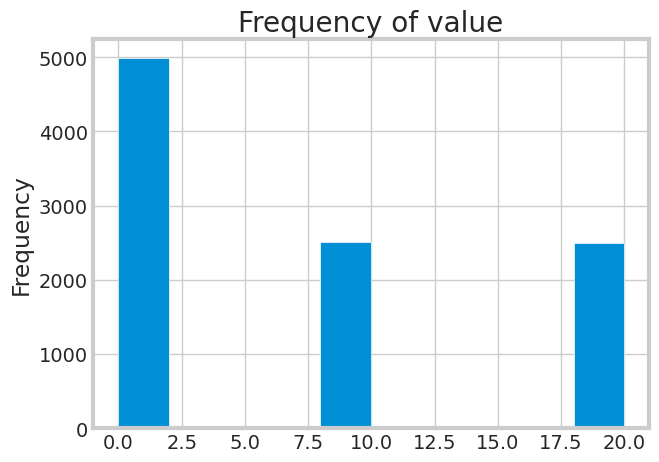

In [39]:
plt.hist(actual_value)
plt.title('Frequency of value')
plt.ylabel('value')
plt.ylabel('Frequency')
plt.show()

In [40]:
df_train, df_test = train_test_split(df,test_size=0.2,random_state=42)
train_idx = df_train.index
test_idx = df_test.index

In [41]:
actual_value[test_idx]

,conversion
6252,20.00
4684,20.00
1731,-0.02
4742,9.98
4521,20.00
...,...
6412,9.98
8285,9.98
7853,9.98
1095,-0.02


In [42]:

random_allocation_value = actual_value[test_idx].mean()

best_ate = df_train.groupby(
    'treatment_group_key')['conversion'].mean().idxmax()

actual_is_best_ate = df_test['treatment_group_key'] == best_ate
best_ate_value = actual_value.loc[test_idx][actual_is_best_ate].mean()

print(f'Random allocation ATE value is: {random_allocation_value:.3f}')
print(f'The best ATE value is: {best_ate_value:.3f}')

Random allocation ATE value is: 7.530
The best ATE value is: 9.980


In [43]:
tm = BaseTClassifier(control_learner=xgb.XGBClassifier(),
                     treatment_learner=xgb.XGBClassifier(),
                     control_name='control')

tm.fit(X=df_train[X_names].values,
       treatment=df_train['treatment_group_key'],
       y=df_train['conversion'])

tm_pred = tm.predict(df_test[X_names].values)
pred_df = pd.DataFrame(tm_pred, columns=tm._classes)
tm_best = pred_df.idxmax(axis=1)
actual_is_tm_best = df_test['treatment_group_key'] == tm_best.ravel()
tm_value = actual_value.loc[test_idx][actual_is_tm_best].mean()

In [44]:
proba_model = xgb.XGBClassifier()

W_dummies = pd.get_dummies(df['treatment_group_key'])
XW = np.c_[df[X_names], W_dummies]

proba_model.fit(XW[train_idx], df_train['conversion'])
y_proba = proba_model.predict_proba(XW[test_idx])[:, 1]

In [45]:
cve = CounterfactualValueEstimator(treatment=df_test['treatment_group_key'],
                                   control_name='control',
                                   treatment_names=conditions[1:],
                                   y_proba=y_proba,
                                   cate=tm_pred,
                                   value=conversion_value_array[test_idx],
                                   conversion_cost=cc_array[test_idx],
                                   impression_cost=ic_array[test_idx])

cve_best_idx = cve.predict_best()
cve_best = [conditions[idx] for idx in cve_best_idx]
actual_is_cve_best = df.loc[test_idx, 'treatment_group_key'] == cve_best
cve_value = actual_value.loc[test_idx][actual_is_cve_best].mean()
print(cve_value)

9.311417840375587


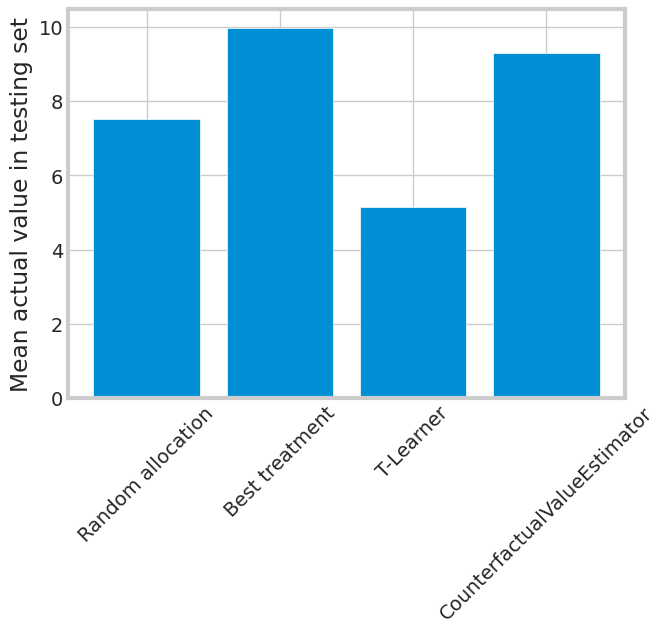

In [46]:
labels = [
    'Random allocation',
    'Best treatment',
    'T-Learner',
    'CounterfactualValueEstimator'
]

values = [
    random_allocation_value,
    best_ate_value,
    tm_value,
    cve_value
]

plt.bar(labels, values)
plt.ylabel('Mean actual value in testing set')
plt.xticks(rotation=45)
plt.show()